<a href="https://colab.research.google.com/github/tomzavi56/South-Africa-Labour-Market-Analysis/blob/main/notebooks/07_time_series_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully.
Shape: (74, 5)


,date,period,year,quarter_number,unemployment_rate
0,2008-01-01,2008Q1,2008,Q1,23.2
1,2008-04-01,2008Q2,2008,Q2,22.6
2,2008-07-01,2008Q3,2008,Q3,22.8
3,2008-10-01,2008Q4,2008,Q4,21.5
4,2009-01-01,2009Q1,2009,Q1,23.0


,date,period,year,quarter_number,unemployment_rate
69,2025-04-01,2025Q2,2025,Q2,33.2
70,2025-07-01,2025Q3,2025,Q3,31.9
71,2025-10-01,2025Q4,2025,Q4,31.4
72,2026-01-01,2026Q1,2026,Q1,32.7
73,2026-04-01,2026Q2,2026,Q2,33.6


Number of observations: 74
Missing values: 0


,unemployment_rate
date,
2008-01-01,23.2
2008-04-01,22.6
2008-07-01,22.8
2008-10-01,21.5
2009-01-01,23.0


...

,unemployment_rate
date,
2024-07-01,32.1
2024-10-01,31.9
2025-01-01,32.9
2025-04-01,33.2
2025-07-01,31.9
2025-10-01,31.4
2026-01-01,32.7
2026-04-01,33.6


,ARIMA_order,MAE,RMSE,AIC
0,"(0, 1, 1)",0.803726,0.972718,232.230771
1,"(1, 1, 1)",0.822428,1.000538,234.085417
2,"(0, 1, 2)",0.825095,1.004881,234.076872
3,"(2, 1, 0)",0.847681,1.029225,234.124834
4,"(1, 1, 0)",0.934261,1.118002,233.116004


,ETS_model,MAE,RMSE
0,ETS - Level only,0.800440,0.968202
1,ETS - Additive trend,1.462400,1.611413
2,ETS - Additive trend and seasonality,1.528215,1.658867


Forecasted unemployment rates:


,0
2026-07-01,33.054832
2026-10-01,33.054832
2027-01-01,33.054832
2027-04-01,33.054832
2027-07-01,33.054832
2027-10-01,33.054832
2028-01-01,33.054832
2028-04-01,33.054832


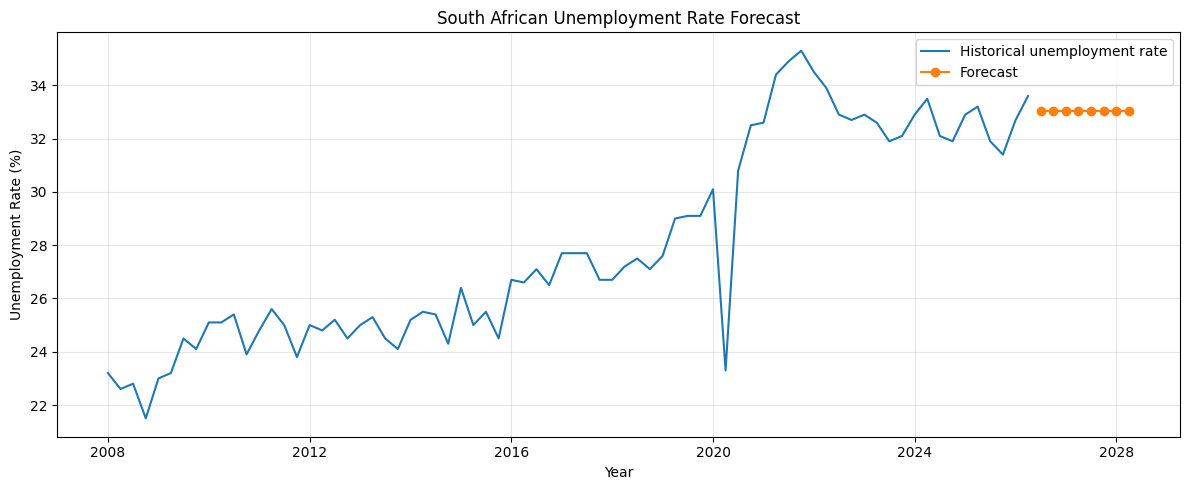

,Model,MAE,RMSE
0,"ARIMA(0,1,1)",0.803726,0.972718
1,ETS - Level only,0.800440,0.968202


In [12]:
# Importing the relevant packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# Loading the cleaned national unemployment dataset

url = "https://raw.githubusercontent.com/tomzavi56/South-Africa-Labour-Market-Analysis/main/data/south_africa_unemployment_2008_2026.csv"

df = pd.read_csv(url)

df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())
display(df.tail())


# Creating the quarterly unemployment time series

ts = df.set_index("date")["unemployment_rate"]

ts = ts.asfreq("QS")

print("Number of observations:", len(ts))
print("Missing values:", ts.isnull().sum())

display(ts.head())

# Performing the Augmented Dickey-Fuller stationarity test

adf_result = adfuller(ts)

print("ADF Statistic:", round(adf_result[0], 4))
print("P-value:", round(adf_result[1], 4))

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {round(value, 4)}")

# Differencing the unemployment series

ts_diff = ts.diff().dropna()

display(ts_diff.head())

# Performing the ADF test on the differenced series

adf_diff_result = adfuller(ts_diff)

print("ADF Statistic:", round(adf_diff_result[0], 4))
print("P-value:", round(adf_diff_result[1], 4))

print("\nCritical Values:")
for key, value in adf_diff_result[4].items():
    print(f"{key}: {round(value, 4)}")

# Splitting the time series into training and testing sets

train = ts.iloc[:-8]
test = ts.iloc[-8:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

display(test)

# Fitting candidate ARIMA models

arima_orders = [
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2)
]

arima_results = []

for order in arima_orders:

    model = ARIMA(
        train,
        order=order
    )

    fitted_model = model.fit()

    forecast = fitted_model.forecast(
        steps=len(test)
    )

    mae = mean_absolute_error(
        test,
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            test,
            forecast
        )
    )

    arima_results.append({
        "ARIMA_order": str(order),
        "MAE": mae,
        "RMSE": rmse,
        "AIC": fitted_model.aic
    })

arima_comparison = pd.DataFrame(
    arima_results
)

arima_comparison = (
    arima_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(arima_comparison)


# Fitting candidate ETS models

ets_results = []

ets_models = {
    "ETS - Level only": {
        "trend": None,
        "seasonal": None
    },

    "ETS - Additive trend": {
        "trend": "add",
        "seasonal": None
    },

    "ETS - Additive trend and seasonality": {
        "trend": "add",
        "seasonal": "add"
    }
}

for name, settings in ets_models.items():

    if settings["seasonal"] is None:
        model = ExponentialSmoothing(
            train,
            trend=settings["trend"],
            seasonal=None
        )
    else:
        model = ExponentialSmoothing(
            train,
            trend=settings["trend"],
            seasonal=settings["seasonal"],
            seasonal_periods=4
        )

    fitted_model = model.fit()

    forecast = fitted_model.forecast(
        len(test)
    )

    mae = mean_absolute_error(
        test,
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            test,
            forecast
        )
    )

    ets_results.append({
        "ETS_model": name,
        "MAE": mae,
        "RMSE": rmse
    })

ets_comparison = pd.DataFrame(
    ets_results
)

ets_comparison = (
    ets_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(ets_comparison)

# Fitting the selected ETS model to the full time series

final_ets_model = ExponentialSmoothing(
    ts,
    trend=None,
    seasonal=None
)

final_ets_fit = final_ets_model.fit()


# Forecasting the next 8 quarters

future_forecast = final_ets_fit.forecast(
    steps=8
)

print("Forecasted unemployment rates:")
display(future_forecast)


# Visualising historical unemployment and the forecast

plt.figure(figsize=(12, 5))

plt.plot(
    ts.index,
    ts,
    label="Historical unemployment rate"
)

plt.plot(
    future_forecast.index,
    future_forecast,
    marker="o",
    label="Forecast"
)

plt.title(
    "South African Unemployment Rate Forecast"
)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Comparing the best ARIMA and ETS models

model_comparison = pd.DataFrame({
    "Model": [
        "ARIMA(0,1,1)",
        "ETS - Level only"
    ],
    "MAE": [
        0.803726,
        0.800440
    ],
    "RMSE": [
        0.972718,
        0.968202
    ]
})

display(model_comparison)